# ISIC 2020 preprocessing (JPEG version)

Reads images **directly from `ISIC_2020_Training_JPEG.zip`** (no need to unzip 24 GB).

What this notebook does, in order:
1. **Clean metadata** from `ISIC_2020_Training_GroundTruth_v2.csv` (has `lesion_id`).
2. **Remove duplicates** using `ISIC_2020_Training_Duplicates.csv` (graph, one image per duplicate group). 33,126 → 32,701.
3. **Make frozen splits** saved as columns (whole team uses the same ones):
   - `split_patient`: train / val / test by **patient** (no patient in two splits), stratified by melanoma.
   - `split_random`: same sizes, plain image-level random split (for the leakage comparison in the proposal).
4. **Image preprocessing**: decode → keep aspect ratio → resize short side to `CACHE_SIZE` (Lanczos) → **center crop** square → optional **Shades-of-Gray color constancy** → `uint8`.
5. Save a **resumable memory-mapped cache** `images_uint8.npy` + `metadata.csv`.

Augmentation and ImageNet normalization happen **during training** (in `train_cnn.ipynb`), not here.

Run from the project folder (where the zip and CSVs are). `isic_utils.py` must be in the same folder.

In [1]:
from pathlib import Path
import json, os, sys, threading, zipfile
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from isic_utils import load_square_rgb

# ------------------------------------------------------------------ settings
CACHE_SIZE      = 256      # square side stored on disk. 256 -> train at 224. Use 384 or 512 for higher-res runs.
COLOR_CONSTANCY = False    # True = Shades-of-Gray. Make one cache each way if you want to ablate it.
TEST_FRAC, VAL_FRAC = 0.15, 0.15
SEED    = 42
WORKERS = max(1, (os.cpu_count() or 2) - 2)
LIMIT   = None             # e.g. 300 for a quick test run; None = all images

ZIP_PATH = ROOT / 'ISIC_2020_Training_JPEG.zip'
GT_PATH  = ROOT / 'ISIC_2020_Training_GroundTruth_v2.csv'
DUP_PATH = ROOT / 'ISIC_2020_Training_Duplicates.csv'
for p in (ZIP_PATH, GT_PATH, DUP_PATH):
    assert p.is_file(), f'Missing {p.name}. Run this notebook from the project folder.'

OUT = ROOT / 'artifacts' / f"jpeg_{CACHE_SIZE}{'_sog' if COLOR_CONSTANCY else ''}{'_debug' if LIMIT else ''}"
OUT.mkdir(parents=True, exist_ok=True)
print('Output folder:', OUT, '| workers:', WORKERS)

Output folder: C:\Users\mahmu\OneDrive\Desktop\Computer Vision\Project\artifacts\jpeg_256 | workers: 10


## 1–2. Metadata and duplicate removal

In [2]:
def connected_components(nodes, edges):
    parent = {n: n for n in nodes}
    def find(n):
        while parent[n] != n:
            parent[n] = parent[parent[n]]
            n = parent[n]
        return n
    for a, b in edges:
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[max(ra, rb)] = min(ra, rb)
    return {n: find(n) for n in parent}

gt = pd.read_csv(GT_PATH).sort_values('image_name').reset_index(drop=True)
dups = pd.read_csv(DUP_PATH)
assert gt['image_name'].is_unique and gt['target'].isin([0, 1]).all()

with zipfile.ZipFile(ZIP_PATH) as z:
    in_zip = {Path(n).stem for n in z.namelist() if n.lower().endswith('.jpg')}
gt['available'] = gt['image_name'].isin(in_zip)
print('Images in CSV:', len(gt), '| found in zip:', int(gt['available'].sum()))

gt['dup_group'] = gt['image_name'].map(connected_components(gt['image_name'], dups.itertuples(index=False, name=None)))
bad = gt.groupby('dup_group')['target'].nunique()
assert not bad.gt(1).any(), f'Duplicate groups with conflicting labels: {bad[bad.gt(1)].index.tolist()}'
assert (gt.groupby('dup_group')['patient_id'].nunique() == 1).all(), 'A duplicate pair spans two patients'

clean = (gt[gt['available']].drop_duplicates('dup_group', keep='first')
         .reset_index(drop=True))
removed = gt[gt['available'] & ~gt['image_name'].isin(clean['image_name'])]
removed.to_csv(OUT / 'removed_duplicates.csv', index=False)
print(f'Removed {len(removed)} duplicates -> {len(clean)} images, {clean.patient_id.nunique()} patients')
print(clean['target'].value_counts().rename({0: 'benign', 1: 'melanoma'}).to_string())

if LIMIT:
    rng = np.random.default_rng(SEED)
    keep = np.r_[rng.choice(np.flatnonzero(clean.target == 1), max(LIMIT // 10, 5), replace=False),
                 rng.choice(np.flatnonzero(clean.target == 0), LIMIT - max(LIMIT // 10, 5), replace=False)]
    clean = clean.iloc[np.sort(keep)].reset_index(drop=True)
    print('DEBUG subset:', len(clean))

Images in CSV: 33126 | found in zip: 33126
Removed 425 duplicates -> 32701 images, 2056 patients
target
benign      32120
melanoma      581


## 3. Frozen splits (patient-level and random)

In [3]:
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

def patient_split(df, frac, seed):
    """Pick ~frac of patients (stratified by melanoma) as the held-out part."""
    k = int(round(1 / frac))
    sgkf = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=seed)
    rest_idx, hold_idx = next(sgkf.split(df, df['target'], groups=df['patient_id']))
    return df.index[rest_idx], df.index[hold_idx]

clean['split_patient'] = 'train'
rest, test = patient_split(clean, TEST_FRAC, SEED)
clean.loc[test, 'split_patient'] = 'test'
_, val = patient_split(clean.loc[rest], VAL_FRAC / (1 - TEST_FRAC), SEED + 1)
clean.loc[val, 'split_patient'] = 'val'

# Plain random split of the same sizes (ignores patients) for the leakage comparison.
n_test, n_val = (clean.split_patient == 'test').sum(), (clean.split_patient == 'val').sum()
tr, te = train_test_split(clean.index, test_size=int(n_test), stratify=clean.target, random_state=SEED)
tr, va = train_test_split(tr, test_size=int(n_val), stratify=clean.loc[tr, 'target'], random_state=SEED)
clean['split_random'] = 'train'
clean.loc[va, 'split_random'] = 'val'
clean.loc[te, 'split_random'] = 'test'

# Leakage checks
sets = {s: set(clean.loc[clean.split_patient == s, 'patient_id']) for s in ['train', 'val', 'test']}
assert not (sets['train'] & sets['val'] or sets['train'] & sets['test'] or sets['val'] & sets['test'])
rand_overlap = set(clean.loc[clean.split_random == 'test', 'patient_id']) & set(clean.loc[clean.split_random == 'train', 'patient_id'])
for col in ['split_patient', 'split_random']:
    print(col); print(clean.groupby(col)['target'].agg(images='size', melanoma='sum', rate='mean').round(4).to_string(), '\n')
print(f'Random split: {len(rand_overlap)} test patients also appear in train (this is the leakage).')

split_patient
               images  melanoma    rate
split_patient                          
test             4674        82  0.0175
train           23364       414  0.0177
val              4663        85  0.0182 

split_random
              images  melanoma    rate
split_random                          
test            4674        83  0.0178
train          23364       415  0.0178
val             4663        83  0.0178 

Random split: 1518 test patients also appear in train (this is the leakage).


## 4–5. Image cache (resumable)
If the run stops, just run this cell again; finished images are skipped.

In [4]:
clean['cache_index'] = np.arange(len(clean))
clean.to_csv(OUT / 'metadata.csv', index=False)

config = {'cache_size': CACHE_SIZE, 'color_constancy': COLOR_CONSTANCY, 'n_images': len(clean),
          'resize': 'aspect-preserving, short side -> size (Lanczos), center crop', 'seed': SEED,
          'source': ZIP_PATH.name, 'labels': GT_PATH.name}
img_path, done_path, man_path = OUT / 'images_uint8.npy', OUT / 'completed.npy', OUT / 'manifest.json'
shape = (len(clean), CACHE_SIZE, CACHE_SIZE, 3)

old = json.loads(man_path.read_text()) if man_path.exists() else {}
if old.get('config') == config and img_path.exists() and done_path.exists():
    images = np.load(img_path, mmap_mode='r+'); done = np.load(done_path, mmap_mode='r+')
else:
    images = np.lib.format.open_memmap(img_path, mode='w+', dtype=np.uint8, shape=shape)
    done = np.lib.format.open_memmap(done_path, mode='w+', dtype=np.bool_, shape=(len(clean),))
    done[:] = False; done.flush()
    man_path.write_text(json.dumps({'config': config, 'complete': False}, indent=2))

_local = threading.local()
def process(i):
    if not hasattr(_local, 'zip'):
        _local.zip = zipfile.ZipFile(ZIP_PATH)   # one zip handle per thread
    data = _local.zip.read(f"train/{clean.at[i, 'image_name']}.jpg")
    return i, load_square_rgb(data, CACHE_SIZE, COLOR_CONSTANCY)

pending = np.flatnonzero(~np.asarray(done))
print(f'Done: {len(clean) - len(pending):,} | to do: {len(pending):,} | cache size {images.nbytes / 1024**3:.2f} GiB')
CHUNK = 256
with ThreadPoolExecutor(WORKERS) as ex:
    for s in tqdm(range(0, len(pending), CHUNK), desc='chunks'):
        batch = pending[s:s + CHUNK]
        for i, arr in ex.map(process, batch):
            images[i] = arr
        images.flush(); done[batch] = True; done.flush()   # mark done only after pixels are written

assert np.asarray(done).all()
man_path.write_text(json.dumps({'config': config, 'complete': True, 'shape': list(shape)}, indent=2))
del images, done
print('Cache complete:', img_path)

Done: 0 | to do: 32,701 | cache size 5.99 GiB


chunks:   0%|          | 0/128 [00:00<?, ?it/s]

Cache complete: C:\Users\mahmu\OneDrive\Desktop\Computer Vision\Project\artifacts\jpeg_256\images_uint8.npy


## 6. Check the cache

Cache verified: (32701, 256, 256, 3)


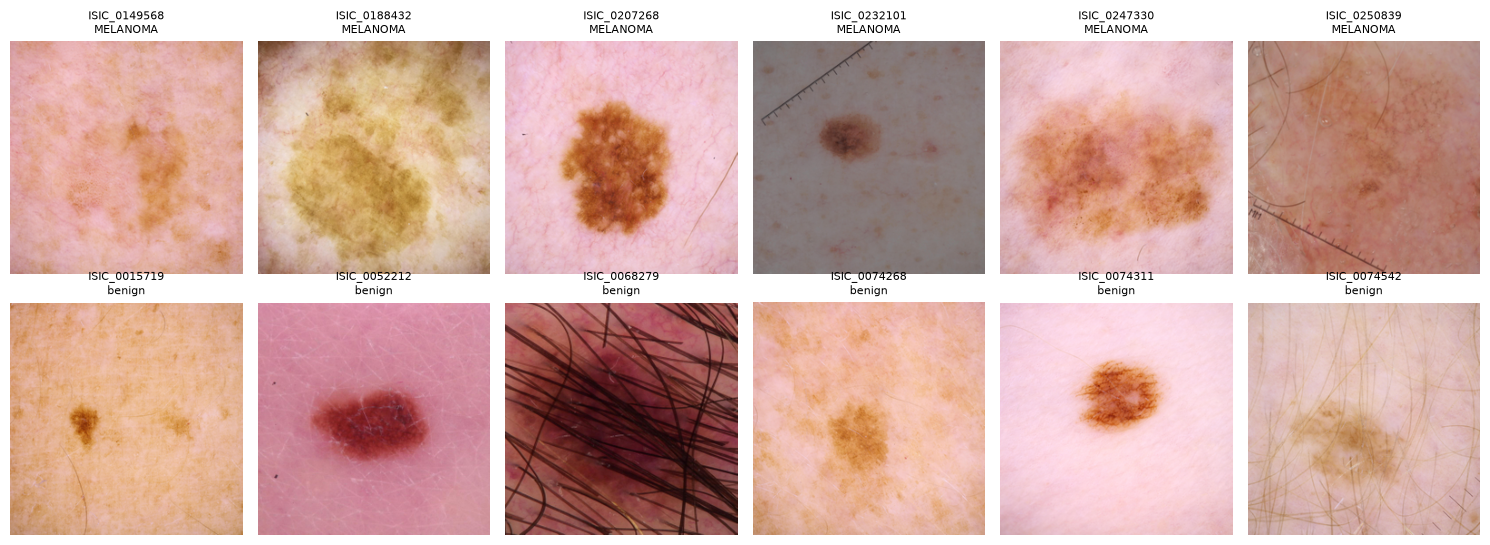

In [5]:
import matplotlib.pyplot as plt

meta = pd.read_csv(OUT / 'metadata.csv')
imgs = np.load(OUT / 'images_uint8.npy', mmap_mode='r')
assert imgs.shape[0] == len(meta) and imgs.dtype == np.uint8

# pixel check: recompute 3 images straight from the zip
with zipfile.ZipFile(ZIP_PATH) as z:
    for i in [0, len(meta) // 2, len(meta) - 1]:
        ref = load_square_rgb(z.read(f"train/{meta.at[i, 'image_name']}.jpg"), CACHE_SIZE, COLOR_CONSTANCY)
        np.testing.assert_array_equal(imgs[i], ref)
print('Cache verified:', imgs.shape)

show = np.r_[np.flatnonzero(meta.target == 1)[:6], np.flatnonzero(meta.target == 0)[:6]]
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for ax, i in zip(axes.ravel(), show):
    ax.imshow(imgs[i]); ax.axis('off')
    ax.set_title(f"{meta.at[i, 'image_name']}\n{'MELANOMA' if meta.at[i, 'target'] else 'benign'}", fontsize=8)
plt.tight_layout(); plt.show()